# 04 · Modelado
**Proyecto Visión por Computador — CRISP-DM etapa 4**

**Tarea:** estimar el **color CIELAB continuo** de la prenda a partir de la foto, **sin máscara manual** en la inferencia. A partir del Lab se deriva el nombre de tono (prototipo más cercano) y la referencia del catálogo (ΔE2000).

Se comparan familias de técnicas del curso, de la más simple a la más elaborada:

| # | Enfoque | ¿Usa máscara al predecir? | Aprende de datos | Tema del curso |
|---|---|---|---|---|
| E1 | **Medición por umbral** (línea base del notebook 01: fondo blanco + mediana Lab) | Sí, por umbral | No | Visión clásica, espacios de color |
| E2 | **Segmentación + k-means** (human parsing + color dominante), con y sin gray-world | Sí, aprendida | No (modelo preentrenado) | Segmentación con DL |
| E3 | **Histograma Lab + ridge** | No | Sí | Descriptores clásicos |
| E4 | **ResNet-50 congelada + ridge** | No | Sí (cabeza lineal) | CNN, transfer learning |
| E5 | **DINOv2-S congelado + ridge** | No | Sí (cabeza lineal) | Auto-supervisado, ViT |
| E6 | **CLIP ViT-B/32 congelado + ridge** | No | Sí (cabeza lineal) | Modelo fundacional |
| E7 | **CLIP zero-shot** (nombre de tono por texto → prototipo) | No | No | Modelo fundacional, zero-shot |
| E8 | **MobileNetV3 fine-tuning** (Lab + grupo auxiliar), aumento geométrico | No | Sí | Fine-tuning, multitarea |
| E9 | **MobileNetV3 fine-tuning + contexto real simulado** (fondos e iluminantes con objetivo fijo) | No | Sí | Aumento de datos con criterio de dominio |
| E10 | **E9 mejorada en GPU**: toda la red ajustada, entrada 224 × 168, 15 épocas, cabeza de 46 tonos, más peso a L*, TTA (reflejo) | No | Sí | Fine-tuning completo, multitarea |
| E11 | **Híbrida "medir en vez de regresar"**: codificador MobileNetV3 + decodificador FPN a resolución nativa; predice un mapa de atención sobre los píxeles del color dominante y la corrección del iluminante, y *mide* el color sobre los píxeles corregidos; pérdida ΔE2000 | No (la red aprende la máscara) | Sí | Segmentación + constancia de color + pérdida perceptual |

**Función de costo (E8, E9):** Huber (Smooth L1) sobre Lab escalado — robusta al ruido residual de etiqueta — más 0,3 × entropía cruzada del grupo básico con *label smoothing* 0,1 (tarea auxiliar que ordena el espacio de representación). Se optimiza con AdamW y *one-cycle*, 6 épocas (los 7 primeros bloques de MobileNetV3 congelados), y se guarda el modelo con menor ΔE en validación.

**E11 (mejora tras analizar el error de E10):** el análisis mostró que el error de E10 ya estaba en las fotos de catálogo (ΔE 3,0) y venía de la *resolución de lectura*: promediar los píxeles del color dominante con su máscara exacta reproduce el objetivo con ΔE ≈ 0,6, pero con la máscara a 1/4 de resolución ya da ≈ 3,8, lo mismo que E10. Una CNN con pooling global no puede escoger píxeles. E11 predice **dónde** está el color dominante (atención a 80 × 60) y **cuál es la luz** (3 ganancias por canal, tipo Von Kries), y calcula el color sobre los píxeles reales: Lab(Σ w · e^g ⊙ RGB lineal) + un residuo pequeño. Se supervisa gratis: la atención con la máscara del color dominante del objetivo y las ganancias con la luz simulada conocida. Pérdida ΔE2000 diferenciable; 40 épocas; el mejor modelo se elige por ΔE2000 en validación **con contexto real**.

**E10 (mejora tras analizar los errores de E9):** el error de E9 en foto de cliente venía más de la claridad (|ΔL*| 3,1) que del croma (2,4), la validación no había convergido en 6 épocas y el nombre del tono se derivaba de prototipos con un techo del 60 %. E10 responde a cada punto: peso 1,5 a L* en la Huber, 15 épocas con toda la red ajustada (en GPU), mayor resolución, una **cabeza de 46 tonos** (+ 0,3 × CE de tono) para predecir el nombre directamente y promedio con la imagen reflejada al predecir.

**Por qué el aumento fotométrico ahora sí es válido (E9):** en el notebook 01 se descartó el ColorJitter porque cambia el color *del objeto*. Aquí se cambia el **iluminante** y el **fondo**, pero el objetivo sigue siendo el color bajo luz neutra: el modelo aprende **constancia de color**, que es justo lo que exige una foto de cliente.

Los cálculos se ejecutan con `ejecutar_pipeline.py` (CPU, ~3 h la primera vez) y quedan en caché; este notebook carga los resultados.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from core import config
from core.datos import decodificar
from core.color import lab_a_rgb

config.RUTA_FIGURAS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "savefig.dpi": 150})
rng = np.random.default_rng(config.SEMILLA)

def guardar(nombre):
    plt.savefig(config.RUTA_FIGURAS / f"{nombre}.png")

import json, torch
from core.preparacion import cargar_prendas, cargar_tabla, RUTA_TEST_REAL
from core.modelos import cargar_red, preparar_tensor
from core.evaluacion import nombres_desde_lab
ok, df, msg = cargar_prendas(); print(msg)
bytes_por_id = df.set_index("id")["imagen_bytes"]
tabla, proto = cargar_tabla()
pred = pd.read_parquet(config.RUTA_RESULTADOS / "predicciones.parquet")
display(pred.groupby(["modelo", "conjunto"]).size().unstack().fillna(0).astype(int))

21,361 prendas en el alcance textil (Apparel)


conjunto,test,test_real,val
modelo,,,
E1_umbral_mediana,3010,3010,0
clip_zeroshot,3010,3010,0
hibrida_e11,3010,3010,0
mobilenet_contexto_real,3010,3010,0
mobilenet_e10,3010,3010,0
mobilenet_estandar,3010,3010,0
ridge_clip_b32,3010,3010,1805
ridge_dinov2_s,3010,3010,1805
ridge_hist_lab,3010,3010,1805


## 1. Datos de entrenamiento

In [2]:
roles = {"train": (tabla["split"] == "train") & tabla["uso_entrenamiento"],
         "val": (tabla["split"] == "val") & tabla["uso_entrenamiento"],
         "test": (tabla["split"] == "test") & tabla["uso_evaluacion"]}
display(pd.DataFrame({k: tabla[m]["grupo_color"].value_counts() for k, m in roles.items()}).fillna(0).astype(int))

,train,val,test
grupo_color,,,
Amarillo,310,66,91
Azul,1729,329,681
Blanco,1805,355,475
Café,394,64,143
Gris,568,116,273
Morado,419,85,163
Naranja,158,31,47
Negro,1787,347,458
Rojo,774,168,267


## 2. Curvas de entrenamiento del fine-tuning

mobilenet_estandar: 2 min de entrenamiento (GPU RTX 4060)
mobilenet_contexto_real: 2 min de entrenamiento (GPU RTX 4060)
mobilenet_e10: 8 min de entrenamiento (GPU RTX 4060)


hibrida_e11: 32 min de entrenamiento (GPU RTX 4060)
E11 · ΔE2000 mediano en validación con contexto real, por época: [6.35, 4.48, 4.05, 4.42, 4.75, 3.47, 3.67, 3.15, 3.65, 3.15, 2.96, 2.91, 3.02, 3.29, 2.65, 2.81, 2.94, 2.92, 2.63, 2.89, 2.57, 2.67, 2.55, 2.44, 2.57, 2.5, 2.48, 2.4, 2.37, 2.41, 2.37, 2.34, 2.42, 2.33, 2.3, 2.31, 2.29, 2.3, 2.32, 2.32]


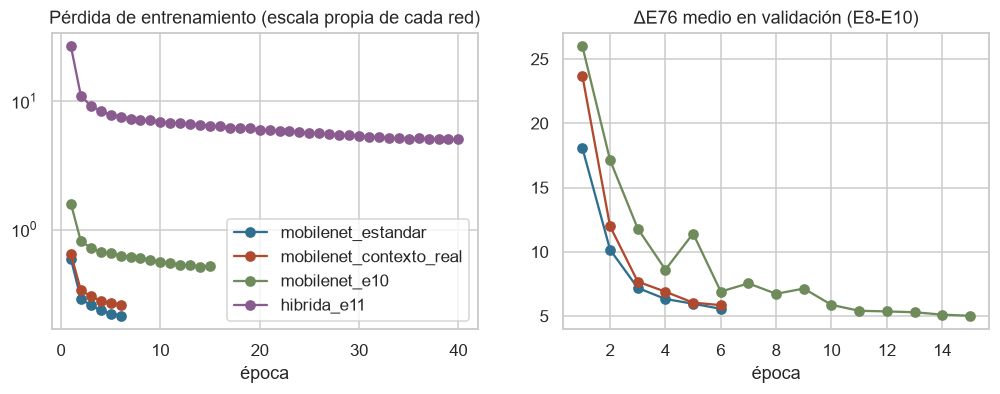

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
import os
for nombre, col in [("mobilenet_estandar", "#2F6F8F"), ("mobilenet_contexto_real", "#B04A2F"), ("mobilenet_e10", "#6F8A5B"), ("hibrida_e11", "#8A5B8F")]:
    if not (config.RUTA_RESULTADOS / f"historia_{nombre}.csv").exists(): continue
    h = pd.read_csv(config.RUTA_RESULTADOS / f"historia_{nombre}.csv")
    axes[0].plot(h["epoca"], h["perdida_train"], "o-", color=col, label=nombre)
    if "dE76_val" in h: axes[1].plot(h["epoca"], h["dE76_val"], "o-", color=col, label=nombre)
    print(f"{nombre}: {h['segundos'].sum() / 60:.0f} min de entrenamiento (GPU RTX 4060)")
axes[0].set(title="Pérdida de entrenamiento (escala propia de cada red)", xlabel="época", yscale="log"); axes[1].set(title="ΔE76 medio en validación (E8-E10)", xlabel="época")
if (config.RUTA_RESULTADOS / "historia_hibrida_e11.csv").exists():
    h11 = pd.read_csv(config.RUTA_RESULTADOS / "historia_hibrida_e11.csv")
    print("E11 · ΔE2000 mediano en validación con contexto real, por época:", h11["dE2000_val_mediana"].round(2).tolist())
axes[0].legend(); guardar("p4_curvas"); plt.show()

## 3. Ejemplo de inferencia: foto de cliente → color → referencias
Cada modelo recibe la foto tal cual (sin máscara) y devuelve un Lab; abajo se muestra el color medido en catálogo (objetivo) y lo que estima cada enfoque sobre la versión "foto de cliente".

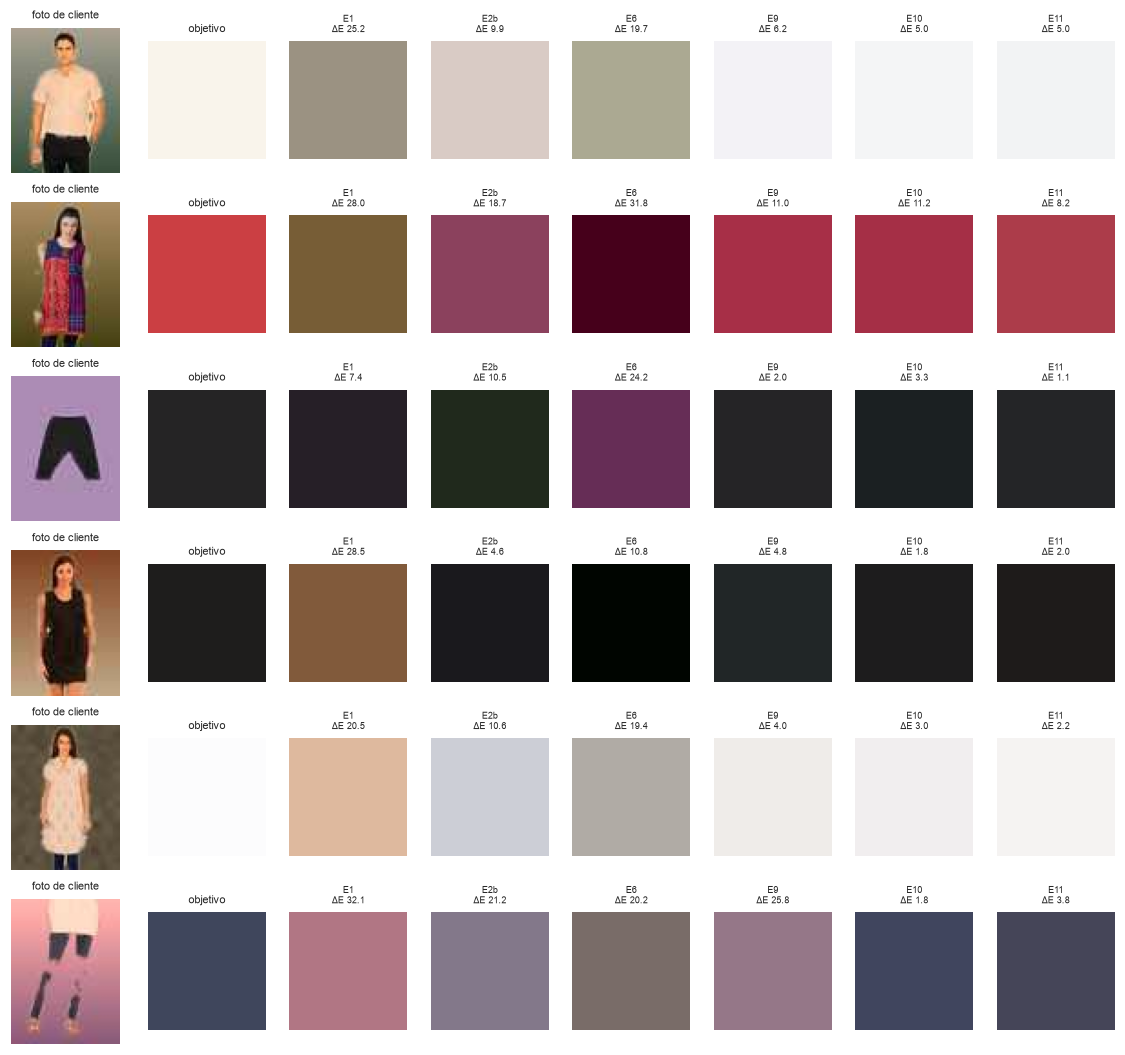

In [4]:
real = pd.read_parquet(RUTA_TEST_REAL).set_index("id")
modelos_ej = [m for m in ["E1_umbral_mediana", "segmentacion_kmeans_grayworld", "ridge_clip_b32", "mobilenet_contexto_real", "mobilenet_e10", "hibrida_e11"]
              if (pred["modelo"] == m).any()]
p_real = pred[pred["conjunto"] == "test_real"].set_index(["modelo", "id"])
ETIQ = {"E1_umbral_mediana": "E1", "segmentacion_kmeans_grayworld": "E2b", "ridge_clip_b32": "E6", "mobilenet_estandar": "E8",
        "mobilenet_contexto_real": "E9", "mobilenet_e10": "E10", "hibrida_e11": "E11"}
ids = tabla[roles["test"] & tabla["coherente"]].sample(6, random_state=9).index
fig, axes = plt.subplots(len(ids), 2 + len(modelos_ej), figsize=(13, 2 * len(ids)))
for fila, pid in zip(axes, ids):
    fila[0].imshow(decodificar(real.at[pid, "imagen_bytes"])); fila[0].set_title("foto de cliente", fontsize=7)
    obj = tabla.loc[pid, ["L_obj", "a_obj", "b_obj"]].to_numpy(float)
    fila[1].imshow(np.ones((4, 4, 3)) * lab_a_rgb(obj)[0]); fila[1].set_title("objetivo", fontsize=7)
    for ax, m in zip(fila[2:], modelos_ej):
        lab = p_real.loc[(m, pid), ["L", "a", "b"]].to_numpy(float)
        from skimage import color as skc
        de = skc.deltaE_ciede2000(lab, obj)
        ax.imshow(np.ones((4, 4, 3)) * lab_a_rgb(lab)[0]); ax.set_title(f"{ETIQ[m]}\nΔE {de:.1f}", fontsize=6)
for ax in axes.flat: ax.axis("off")
guardar("p4_ejemplo_inferencia"); plt.show()

## 4. Cómo se usaría en el área comercial
```python
from core.modelos import cargar_red, preparar_tensor
red = cargar_red(Path("modelos/mobilenet_e10.pt"))            # arquitectura leída de mobilenet_e10.json
lab, grupo, tono = red(preparar_tensor(foto_del_cliente, tam=red.tam)[None])   # color Lab + nombre
referencias = catalogo.ΔE2000(lab).nsmallest(3)              # top-3 del catálogo de colorantes
```
Para prendas multicolor se agrega la paleta de la segmentación (notebook 02, §6) y el asesor elige qué color igualar.